# Atlas Python Package

`moth-atlas` is a client SDK for accessing Moth APIs:

1. **Jobs** - Engine runs identified by `job_id`
2. **Engines** - A registered quantum program with a fixed `engine_id`
3. **Assets** - Files uploaded or produced by a job, identified by `asset_id`

## Install the package
Installs from PyPI. Also works with `uv add moth-atlas`

In [ ]:
%pip install moth-atlas

## Pre-requisite
Set the `MOTH_API_KEY` environment variable. Create a key at [platform.mothquantum.com/keys](https://platform.mothquantum.com/keys).

In [3]:
import os
import getpass

if not os.environ.get("MOTH_API_KEY"):
    os.environ["MOTH_API_KEY"] = getpass.getpass("Atlas API key")

Atlas API key ········


## Import Atlas

In [4]:
import moth_atlas
print(moth_atlas.__version__)

0.3.0


## Setup Client

In [5]:
client = moth_atlas.Atlas()  # reads MOTH_API_KEY

In [9]:
# Verify client (optional)
# print(f"Pointing to {client.base_url}")
# print(f"Using {client.me().email}")

## Run an engine

In [7]:
job = client.jobs.run("coin-toss-v1")
print(job.result)

coin-toss-v1 job c62ca87c submitted
coin-toss-v1 job c62ca87c completed (2s)
{'backend': 'aer', 'heads': 5, 'ibm_job_id': '7b874766412047eaa0ebfdbac79d6514', 'io': {'backend': None, 'dynamical_decoupling': None, 'emu_trajectories': None, 'error_mitigation': None, 'initial_layout': None, 'layout': None, 'mode': 'sim', 'optimization_level': None, 'precision': None, 'provider': None, 'routing': None, 'seed': None, 'seed_sampler': None, 'seed_transpiler': None, 'shots': 10, 'sim_noise': None, 'store': True, 'time_budget': False, 'transpile_mode': None, 'twirling': None}, 'io_report': {'applied': ['backend=None', 'mode=sim', 'provider=None', 'shots=10', 'store=True', 'time_budget=False'], 'ignored': [], 'unsupported': []}, 'mode': 'emu', 'output': 'heads', 'shots': 10, 'tails': 5}


### Pass parameters using `params` field

In [8]:
job = client.jobs.run(engine="coin-toss-v1",
                      params={
                          "shots": 1000,
                      })
print(job)
print(job.result)

coin-toss-v1 job c6a0dd0b submitted
coin-toss-v1 job c6a0dd0b completed (2s)
Job(job_id='c6a0dd0b-2a89-4cc6-966a-1bcc29d355fc', engine_id='coin-toss-v1', status='completed', result={'backend': 'aer', 'heads': 522, 'ibm_job_id': 'e90e8098c57e46b092451b1f1230573…)
{'backend': 'aer', 'heads': 522, 'ibm_job_id': 'e90e8098c57e46b092451b1f1230573d', 'io': {'backend': None, 'dynamical_decoupling': None, 'emu_trajectories': None, 'error_mitigation': None, 'initial_layout': None, 'layout': None, 'mode': 'sim', 'optimization_level': None, 'precision': None, 'provider': None, 'routing': None, 'seed': None, 'seed_sampler': None, 'seed_transpiler': None, 'shots': 1000, 'sim_noise': None, 'store': True, 'time_budget': False, 'transpile_mode': None, 'twirling': None}, 'io_report': {'applied': ['backend=None', 'mode=sim', 'provider=None', 'shots=1000', 'store=True', 'time_budget=False'], 'ignored': [], 'unsupported': []}, 'mode': 'emu', 'output': 'heads', 'shots': 1000, 'tails': 478}


### Pass files using `files` field
Any image path of your own works too.

blur-v1 job 60fdd2c3 submitted
blur-v1 job 60fdd2c3 completed (4s)
Job(job_id='60fdd2c3-d45a-4224-ab52-b4788f656d24', engine_id='blur-v1', status='completed', outputs=['result'])
result: blur-v1-60fdd2c3.png (image/png, 107.9 KB)



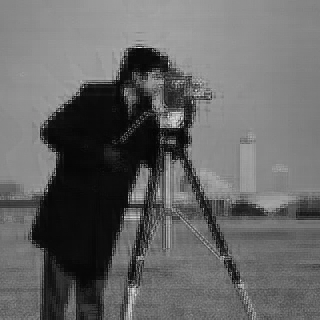

In [10]:
job = client.jobs.run(engine="blur-v1",
                      params={
                          "strength": 0.5,
                      },
                      files={
                          "image": "blur/cat.png",
                      })
print(job)
job.show()

### Access docstrings of any method

In [11]:
help(client.jobs.run)

Help on method run in module moth_atlas.jobs:

run(engine: 'Engine | str', params: 'dict[str, Any] | None' = None, files: 'dict[str, FileInput] | None' = None, mode: 'str | None' = None, timeout: 'float | None' = None, on_update: 'Callable[[Job], None] | None' = None, quiet: 'bool' = False, wait: 'bool' = True) -> 'Job' method of moth_atlas.jobs.Jobs instance
    Upload ``files``, submit, and wait: the one-call way to run an engine.

    Args:
        engine: An ``Engine``, or an engine ID such as ``"blur-v1"``.
        params: Engine parameters, as described by ``engines.get(engine).params_schema``.
        files: Maps the engine's input slots to files, e.g. ``{"image": "cat.png"}``. Each file is
            anything ``assets.upload`` accepts (a path, bytes, an open binary file, or a
            ``(filename, bytes, content_type)`` tuple), or an ``Asset`` already uploaded.
        mode: Platform-reserved execution target; leave unset.
        timeout: Passed to ``wait``.
        on_upd

## Assets

In [17]:
asset = client.assets.upload(file="blur/image2.png") # assets are cached per session to avoid re-uploading
print(asset.asset_id)

9c5418e8-7928-43cd-a0bb-edf78a26d30d


### Use assets (optional)

In [ ]:
job = client.jobs.run(engine="blur-v1",
                      params={
                          "strength": 0.5,
                      },
                      files={
                          "image": asset,
                      })
job.show()

## Browse engines

In [ ]:
list(client.engines.list())

### Expand an engine

In [16]:
blur = client.engines.get("blur-v1")
blur

**blur-v1** · Quantum Blur · v1.2.0 · 1 credit per run

Apply a quantum blur algorithm to the image.

**Params**

| param | type | default | range | description |
|---|---|---|---|---|
| backend | string \| null | None |   | Device name for `emu`/`qpu` (e.g. `fez`, `marrakesh`, `garnet`). `emu` resolves it to the device's … |
| downscale | boolean | True |   | Strategy used when a mask region is larger than the maximum number of qubits allows: - `true` — the… |
| execution_mode | 'sim' \| 'emu' \| 'qpu' \| 'local' | 'sim' |   | Where the quantum blur runs, through moth_backbone: - `sim` - exact statevector simulation (default… |
| io | object \| null | None |   | Standard moth_backbone execution block: mode (sim \| emu \| qpu), provider (ibm \| iqm), backend, shot… |
| machine | string \| null | None |   | Platform shorthand for where to run, one key instead of execution_mode / provider / backend: `aer` … |
| mask_bin_size | number \| null | 4 | >= 0, <= 100 | Mask quantisation step as a percentage of 255 (0–100). Pixel values below this threshold are treate… |
| mask_min_region | integer \| null | 16 | >= 1 | Minimum mask region size in pixels. Connected components smaller than this are discarded after quan… |
| provider | 'aer' \| 'ibm' \| 'iqm' | 'aer' |   | Provider for `emu`/`qpu`: `ibm` or `iqm`. Ignored for `sim`/`local` (always aer). |
| reach | number | 0 | >= 0, <= 1 | Controls how far from its original position a pixel can be affected by the blur: - `0` — fully loca… |
| shots | integer | 4096 | >= 1, <= 100000 | Measurements per circuit on `emu`/`qpu` - the blur is estimated from them, so more shots = less noi… |
| size | integer | 1024 | >= 8, <= 1024 | Pixel budget per blur pass: a region up to `size × size` pixels is blurred in a single pass. Intern… |
| store_results | boolean | True |   | Store every executed circuit (result, fidelity, calibration) through moth_backbone. |
| strength | number | 0.5 | >= 0, <= 1 | Strength of the effect, which controls the rotation applied to each qubit: - `0` — the image is lef… |
| style | 'rx' \| 'ry' | 'rx' |   | Quantum gate used to apply the effect: - `rx` — rotation around the x-axis of the Bloch sphere. - `… |

**Input files**

| slot | required | types | description |
|---|---|---|---|
| image | required | image/png, image/jpeg, image/webp, image/tiff, image/bmp | The image of your choice. The blur effect is applied RGB pixel values only, not the alpha channel. … |
| mask | optional | image/png, image/jpeg, image/webp, image/tiff, image/bmp | Optional mask controlling where the effect is applied, on a per-pixel basis. Must match the size of… |

**Returns files (job.outputs)**

| slot | types | description |
|---|---|---|
| result | image/png, image/jpeg, image/webp, image/tiff, image/bmp | The processed image. |

**Example**

```python
job = client.jobs.run(
    engine="blur-v1",
    params={
        "downscale": True,
        "execution_mode": "sim",
        "mask_bin_size": 4,
        "mask_min_region": 16,
        "provider": "aer",
        "reach": 0,
        "shots": 4096,
        "size": 1024,
        "store_results": True,
        "strength": 0.5,
        "style": "rx",
    },
    files={
        "image": "image.png",
    },
)
```

Full docs: `engine.description_md`